# Assignment 5: Four models of a bioreactor
**Released:** L15 (2026-10-21) · **Due:** Wednesday 2026-10-28 · **6 points on Canvas.**

Exporting and submitting your homework

0. Work in Google Colab. Open this notebook from [this link](https://colab.research.google.com/github/jkitchin/f26-06763/blob/main/course/assignments/a05.ipynb) (or "Open in Colab" on the course page), then File > Save a copy in Drive, and work in your copy.

1. Run every cell from top to bottom (Runtime > Run all), so that all outputs and plots are in the notebook.

2. Export the notebook as a PDF: File > Print, then choose "Save as PDF" as the destination.

3. Check the PDF before you submit it. It is your responsibility to make sure the PDF exported correctly: every code cell, output, plot and answer must be in it and readable. Equations from the problem statement need not render perfectly, as long as your answers are clear.

4. Submit the PDF to Canvas.

Consider a continuous bioreactor in which the biomass (cells) grows by consuming substrate. Five experiments were run on it, each from a different initial condition. Build four models, use each one to predict experiment 5, and compare the predictions:

| Problem | Model | Learns from | Taught in | Points |
|---|---|---|---|---|
| 1 | Neural-network time-series model | Experiments 1 to 4 | [Lecture 8](https://kitchingroup.cheme.cmu.edu/f26-06763/lectures/l08/notes.html), [Lecture 9](https://kitchingroup.cheme.cmu.edu/f26-06763/lectures/l09/notes.html) | 1 |
| 2 | Neural network of time, $t \mapsto (X, S)$ | The first 40 s of experiment 5 | [Lecture 13](https://kitchingroup.cheme.cmu.edu/f26-06763/lectures/l13/notes.html), [`l13-pinn-jax.ipynb`](https://kitchingroup.cheme.cmu.edu/f26-06763/lectures/l13/l13-pinn-jax.html) | 1 |
| 3 | Physics-informed neural network (PINN) | The first 40 s of experiment 5, and the two balances | [Lecture 13](https://kitchingroup.cheme.cmu.edu/f26-06763/lectures/l13/notes.html), [`l13-pinn-jax.ipynb`](https://kitchingroup.cheme.cmu.edu/f26-06763/lectures/l13/l13-pinn-jax.html) | 1.5 |
| 4 | Neural ODE (ordinary differential equation) | Experiments 1 to 4, and the biomass balance | [Lecture 13](https://kitchingroup.cheme.cmu.edu/f26-06763/lectures/l13/notes.html), [`l13-neural-dae.ipynb`](https://kitchingroup.cheme.cmu.edu/f26-06763/lectures/l13/l13-neural-dae.html) | 1.5 |
| 5 | Comparison | | | 1 |

Your TA grades the PDF. A model that fails, reported and explained, loses no points.

## The bioreactor

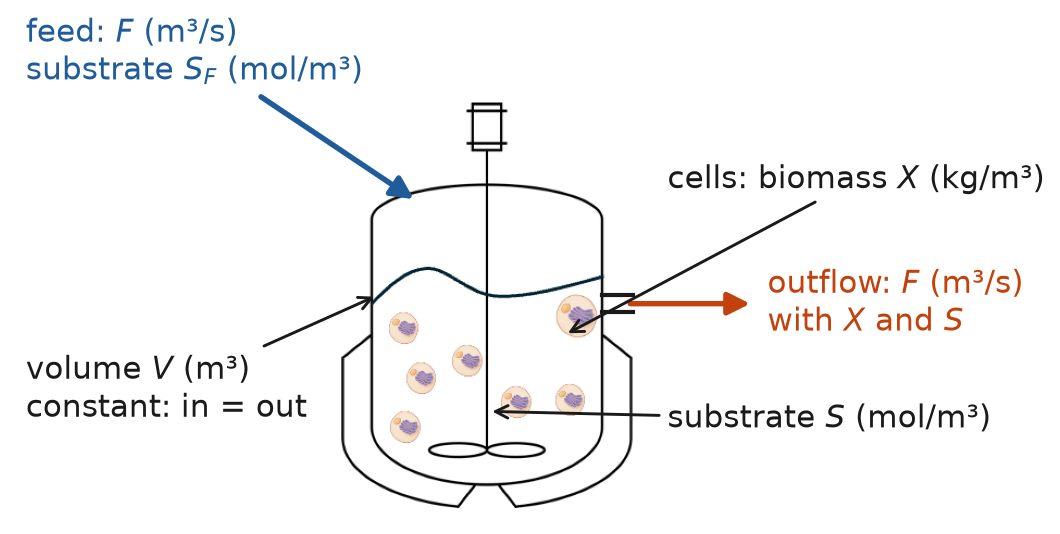

The feed enters at rate $F$ with substrate concentration $S_F$. The outflow leaves at the same rate, at the reactor concentrations $X$ and $S$, so the volume $V$ is constant.

The model consists of two dynamic mass balances, one for the biomass $X$ and one for the substrate $S$:

$$
\frac{dX}{dt} = \underbrace{-\frac{F}{V}\,X}_{\text{outflow}} + \underbrace{\mu(S)\,X}_{\text{growth}}
$$

$$
\frac{dS}{dt} = \underbrace{\frac{F}{V}\,(S_F - S)}_{\text{feed} - \text{outflow}} - \underbrace{\frac{\mu(S)}{Y(S)}\,X}_{\text{consumption}}
$$

where $\mu(S)$ is the specific growth rate and $Y(S)$ the yield:

$$
\mu(S) = 10^{-3}\,S\,e^{-S/120}, \qquad Y(S) = 5.4 \cdot 10^{-3} + 1.8 \cdot 10^{-4}\,S
$$

| Symbol | Meaning | Value | Units |
|---|---|---|---|
| $X$ | Biomass concentration | state | kg/m³ |
| $S$ | Substrate concentration | state | mol/m³ |
| $\mu(S)$ | Specific growth rate | equation above | 1/s |
| $Y(S)$ | Yield: biomass made per substrate consumed | equation above | kg/mol |
| $V$ | Reactor volume | $\pi \cdot 3^2 \cdot 5.7$ | m³ |
| $F$ | Feed and outflow rate | 5.02597 | m³/s |
| $S_F$ | Substrate concentration in the feed | 300 | mol/m³ |

## The data

- Columns: `experiment` (1 to 5), `t` (s), `X` (kg/m³), `S` (mol/m³). One sample every 5 s.
- Experiments 1 to 4: 0 to 100 s, 21 samples each.
- Experiment 5: 0 to 300 s, 61 samples. Problems 2 and 3 train on its first 40 s. Its measurements after 40 s are the test.
- The first sample of each experiment ($t = 0$) is the exact initial condition. The others are measurements with Gaussian noise: standard deviation 0.05 kg/m³ on $X$ and 1 mol/m³ on $S$.

| Experiment | $X_0$ (kg/m³) | $S_0$ (mol/m³) | Measured | Use |
|---|---|---|---|---|
| 1 | 5.0 | 10 | 0 to 100 s | Training |
| 2 | 2.0 | 20 | 0 to 100 s | Training |
| 3 | 4.0 | 120 | 0 to 100 s | Training |
| 4 | 2.5 | 60 | 0 to 100 s | Training |
| 5 | 3.0 | 80 | 0 to 300 s | First 40 s: training for Problems 2 and 3. After 40 s: **test** |

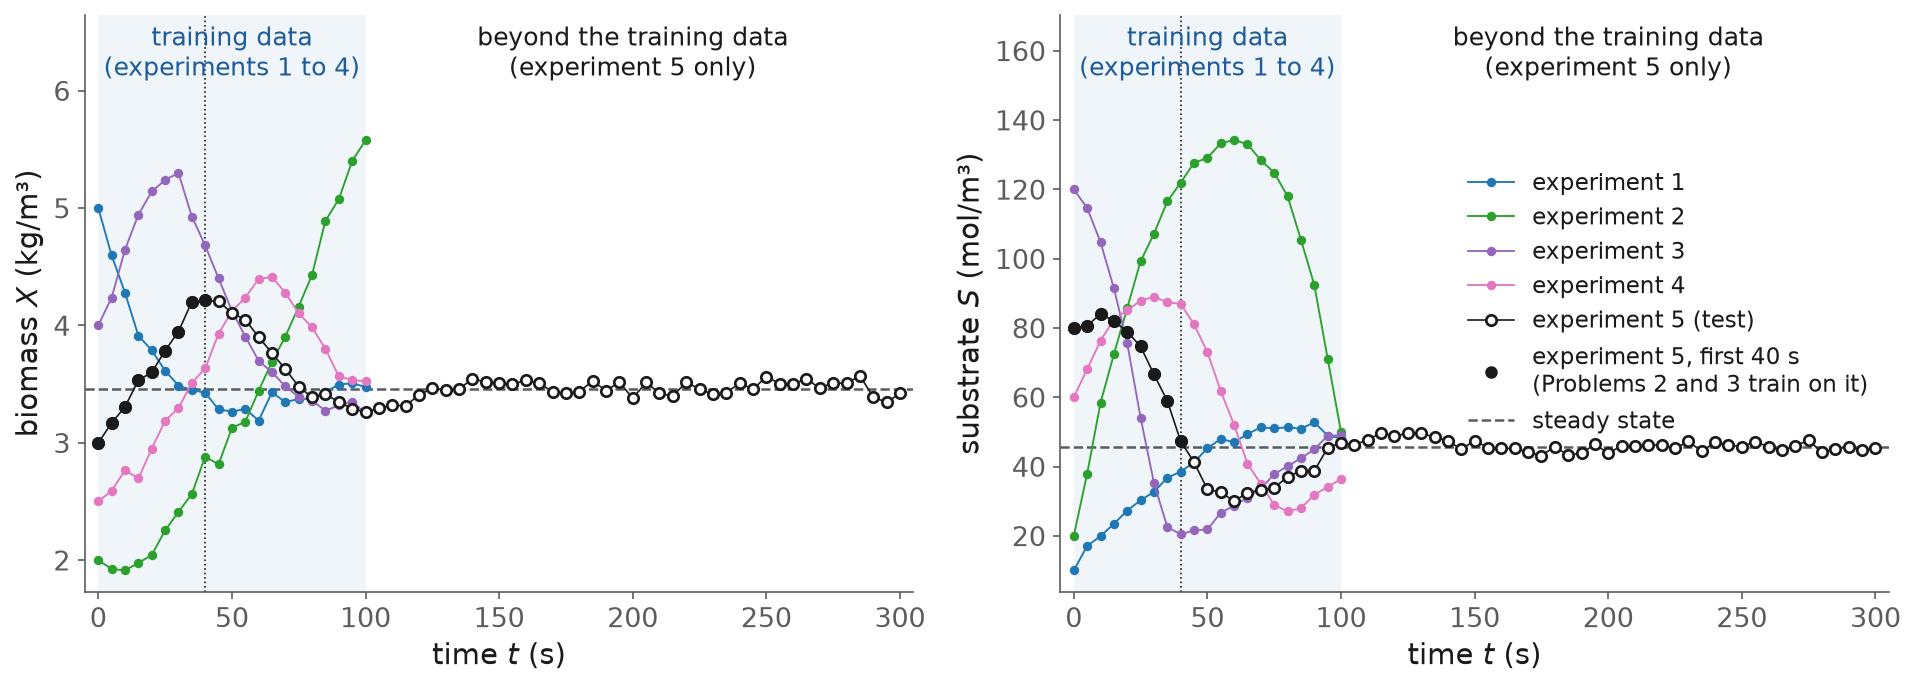

The training data: experiments 1 to 4 (0 to 100 s), and the first 40 s of experiment 5 for Problems 2 and 3. The test: experiment 5 after 40 s.

## Set-up

Run the two cells below first. The first installs the two packages Colab does not have. The second loads the libraries, the data and the model's parameters.

In [ ]:
!pip install -q equinox diffrax optax

In [ ]:
import diffrax                      # ODE solvers in JAX (Lecture 13)
import equinox as eqx               # neural networks in JAX (Lecture 13)
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax                        # optimizers for JAX (Lectures 11 and 13)
import pandas as pd
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# double precision (Lecture 11)
jax.config.update("jax_enable_x64", True)

# the data: columns experiment, t (s), X (kg/m3), S (mol/m3)
df = pd.read_csv("https://kitchingroup.cheme.cmu.edu/f26-06763/a05-bioreactor.csv")

# the model's parameters
V = np.pi * 3**2 * 5.7      # m3
F = 5.02597                 # m3/s
SF = 300.0                  # mol/m3


def mu(S):
    # specific growth rate (1/s)
    return 1e-3 * S * jnp.exp(-S / 120)


def Y(S):
    # yield (kg/mol)
    return 5.4e-3 + 1.8e-4 * S

## Notes for all problems
- **Problems 1 and 4** train on experiments 1 to 4. From experiment 5 they use only its initial condition, $(X_0, S_0) = (3.0, 80)$.
- **Problems 2 and 3** train on experiment 5 from 0 to 40 s, its first 9 samples. A network of $t$ describes one trajectory, so its data must come from the trajectory it predicts.
- Every model predicts experiment 5 at $t = 0, 5, \ldots, 300$ s. Its measurements after 40 s are the test, in Problem 5.
- JAX takes NumPy arrays, not pandas columns. Read the times as floats with `df["t"].astype(float).to_numpy()`, because `jax.grad` refuses integers and the column `t` holds integers. Read `X` and `S` with `.to_numpy()` too.
- Build time grids with `np.linspace` (Lecture 13), which gives floats.
- Inside a function that JAX differentiates or integrates, write the math with `jnp` (`jnp.exp`), not `np`.
- The L13 notebooks import packages A5 does not need (`pyomo`, `sindae`). Copy only the cells you need.
- A model is allowed to fail. Report what you get and explain it.

## 1. Neural-network time-series model
Consider a model that predicts the next sample from the current one:

$$
X_{k+1} = f_X(X_k, S_k), \qquad S_{k+1} = f_S(X_k, S_k)
$$

It is the recursive time-series model of [Lecture 8](https://kitchingroup.cheme.cmu.edu/f26-06763/lectures/l08/notes.html), with a neural network ([Lecture 9](https://kitchingroup.cheme.cmu.edu/f26-06763/lectures/l09/notes.html)) as the regression.

Using experiments 1 to 4, do the following:

a) Build the training table: features $X_k$ and $S_k$, targets $X_{k+1}$ and $S_{k+1}$. That is 20 rows per experiment, 80 in total.

Hint: one experiment at a time. For an array `arr` of its 21 samples, the features are `arr[:-1]` and the targets are `arr[1:]`.

In [ ]:
# ADD YOUR CODE HERE  -- feel free to add additional code or markdown blocks if needed 


b) Fit $f_X$ and $f_S$, each with `make_pipeline(StandardScaler(), MLPRegressor(solver="lbfgs", random_state=0, max_iter=5000))` (scikit-learn; Lectures 8 and 9).

In [ ]:
# ADD YOUR CODE HERE  -- feel free to add additional code or markdown blocks if needed 


c) Predict experiment 5 recursively (Lecture 8, "Direct and recursive forecasting"). Start from $(3.0, 80)$. At each step, predict $X_{k+1}$ and $S_{k+1}$ from the same $(X_k, S_k)$, then use the pair as the next features. Repeat 60 times.

In [ ]:
# ADD YOUR CODE HERE  -- feel free to add additional code or markdown blocks if needed 


d) Plot $X$ and $S$ of your prediction with the measurements of experiment 5. How good is the prediction? Why?

In [ ]:
# ADD YOUR CODE HERE  -- feel free to add additional code or markdown blocks if needed 


## 2. Neural network of time
Consider the plain network of Lecture 13: a neural network that maps time to the states, $t \mapsto (X, S)$, trained on data only.

a) Run the cell below. It codes the network:

In [ ]:
net = eqx.nn.MLP(              # t -> (X, S)
    in_size=1,
    out_size=2,
    width_size=32,
    depth=3,
    activation=jnp.tanh,
    key=jax.random.PRNGKey(0),
)


def model(net, t):
    # X and S of experiment 5 at time t (s)
    return net(jnp.array([t]))

b) Train it on the 9 samples of experiment 5 from 0 to 40 s. In the cell below, build `t_fit`, their 9 times, and `y_fit`, their 9 rows of $(X, S)$, as NumPy arrays.

In [ ]:
# ADD YOUR CODE HERE  -- feel free to add additional code or markdown blocks if needed 


Then run the cell below. It defines the loss, the mean squared error against the 9 samples, and a training function, and trains the network:
- `jax.vmap` (JAX; Lectures 11 and 13) evaluates `model` at all 9 times at once.
- `train` is the training step of `l13-neural-dae.ipynb` (Equinox and Optax; Lecture 13) inside a function, so that Problems 3 and 4 can call it with their own loss. The step of `l13-pinn-jax.ipynb` does not work on an Equinox network.

In [ ]:
def loss_nn(net):
    # mean squared error against the 9 samples: times t_fit, values y_fit
    pred = jax.vmap(model, in_axes=(None, 0))(net, t_fit)
    return jnp.mean((pred - y_fit) ** 2)


def train(loss, net, steps, opt):
    # the training step of l13-neural-dae.ipynb, for any loss
    state = opt.init(eqx.filter(net, eqx.is_array))

    @eqx.filter_jit
    def step(net, state):
        value, grads = eqx.filter_value_and_grad(loss)(net)
        updates, state = opt.update(grads, state, net)
        return eqx.apply_updates(net, updates), state, value

    for _ in range(steps):
        net, state, value = step(net, state)
    return net


net_nn = train(loss_nn, net, 20_000, optax.adam(1e-3))

c) Evaluate `net_nn` at $t = 0, 5, \ldots, 300$ s with `jax.vmap(model, in_axes=(None, 0))`. Plot $X$ and $S$ with the measurements, marking the 40 s it trained on. How good is it before 40 s, and after? Why?

In [ ]:
# ADD YOUR CODE HERE  -- feel free to add additional code or markdown blocks if needed 


## 3. PINN
Consider the PINN of Lecture 13: the network of Problem 2, trained on the same data and on the residuals of the model's equations. For this reactor the residuals are

$$
r_X = \frac{dX}{dt} + \frac{F}{V}\,X - \mu(S)\,X, \qquad
r_S = \frac{dS}{dt} - \frac{F}{V}\,(S_F - S) + \frac{\mu(S)}{Y(S)}\,X
$$

with $X$ and $S$ the network's outputs.

a) Run the cell below. It codes the residuals. $dX/dt$ and $dS/dt$ come from `jax.grad` (JAX; Lectures 11 and 13) of each output with respect to $t$.

In [ ]:
def residuals(net, t):
    X, S = model(net, t)
    # dX/dt and dS/dt: jax.grad of each output with respect to t
    dXdt = jax.grad(lambda t: model(net, t)[0])(t)
    dSdt = jax.grad(lambda t: model(net, t)[1])(t)
    rX = dXdt + F / V * X - mu(S) * X
    rS = dSdt - F / V * (SF - S) + mu(S) / Y(S) * X
    return jnp.array([rX, rS])

b) Run the cell below. It trains the PINN with `train`, from the same starting network `net`, on data plus physics. The loss is $\mathcal{L}_\text{data} + \mathcal{L}_\text{physics}$: the loss of Problem 2, plus the mean of $r_X^2 + r_S^2$ at 301 collocation points from 0 to 300 s.

In [ ]:
t_phys = np.linspace(0, 300, 301)       # 301 collocation points (s)


def loss_pinn(net):
    # the residuals at every collocation point
    r = jax.vmap(residuals, in_axes=(None, 0))(net, t_phys)
    return loss_nn(net) + jnp.mean(r[:, 0] ** 2 + r[:, 1] ** 2)


net_pinn = train(loss_pinn, net, 20_000, optax.adam(1e-3))

c) Evaluate `net_pinn` at $t = 0, 5, \ldots, 300$ s and plot it with the measurements and the prediction of Problem 2. How good is it after 40 s, compared with Problem 2? Why does the physics help? Why is the prediction still off?

In [ ]:
# ADD YOUR CODE HERE  -- feel free to add additional code or markdown blocks if needed 


## 4. Neural ODE
Consider the same balances with two networks: $\mu_\text{NN}(S)$, the growth rate in the biomass balance, and $f_\text{NN}(X, S)$, the whole right-hand side of the substrate balance:

$$
\frac{dX}{dt} = -\frac{F}{V}\,X + \mu_\text{NN}(S)\,X, \qquad
\frac{dS}{dt} = f_\text{NN}(X, S)
$$

The biomass balance keeps its physics. Nothing of the substrate balance is given. The code follows [`l13-neural-dae.ipynb`](https://kitchingroup.cheme.cmu.edu/f26-06763/lectures/l13/l13-neural-dae.html).

a) Run the cell below. It codes the two networks and the right-hand side:

In [ ]:
mu_net = eqx.nn.MLP(           # S -> growth rate mu
    in_size=1,
    out_size=1,
    width_size=16,
    depth=2,
    activation=jnp.tanh,
    key=jax.random.PRNGKey(0),
)
f_net = eqx.nn.MLP(            # (X, S) -> dS/dt
    in_size=2,
    out_size=1,
    width_size=16,
    depth=2,
    activation=jnp.tanh,
    key=jax.random.PRNGKey(1),
)
nets = (mu_net, f_net)


def mu_nn(mu_net, S):
    # growth rate (1/s): positive, and of the size of the true mu (at most 0.044)
    return 0.05 * jax.nn.softplus(mu_net(jnp.array([S / 100]))[0])


def balances(t, x, nets):
    mu_net, f_net = nets
    X, S = x
    # biomass balance, with mu learned
    dXdt = -F / V * X + mu_nn(mu_net, S) * X
    # substrate balance, learned whole
    dSdt = f_net(jnp.array([X / 5, S / 100]))[0]
    return jnp.array([dXdt, dSdt])

b) Run the cell below. It simulates with `diffrax.diffeqsolve` (Diffrax; Lecture 13):

In [ ]:
def simulate(nets, x0, ts):
    # X and S at the times ts, from the initial condition x0
    sol = diffrax.diffeqsolve(
        diffrax.ODETerm(balances),
        diffrax.Tsit5(),
        t0=0.0,
        t1=ts[-1],
        dt0=0.5,
        y0=x0,
        args=nets,
        saveat=diffrax.SaveAt(ts=ts),
        stepsize_controller=diffrax.PIDController(
            rtol=1e-6,
            atol=1e-8,
        ),
    )
    return sol.ys

c) Train on experiments 1 to 4. In the cell below, define:
- `x0s`, their four initial conditions, `ts`, their 21 sample times, and `ys`, their measurements, of shape (4, 21, 2);
- `sigma`, the standard deviation of $X$ and of $S$ over all samples of experiments 1 to 4;
- `loss_node(nets)`: simulate the four experiments at once with `jax.vmap(simulate, in_axes=(None, 0, None))(nets, x0s, ts)`, and return the mean of $\left((\text{prediction} - \text{data}) / \sigma\right)^2$.

In [ ]:
# ADD YOUR CODE HERE  -- feel free to add additional code or markdown blocks if needed 


Then run the cell below. It trains for 10,000 steps with `train` and a cosine schedule (Optax; Lecture 13). `train` accepts the pair `nets`, because `eqx.filter` and `eqx.filter_value_and_grad` work on a tuple of networks.

In [ ]:
opt = optax.adam(optax.cosine_decay_schedule(1e-2, 10_000, alpha=0.05))
nets = train(loss_node, nets, 10_000, opt)

d) Predict experiment 5 by integrating from its initial condition with `simulate`. It is a new initial-value problem: do not retrain, and use only its initial condition. Plot it with the measurements.

In [ ]:
# ADD YOUR CODE HERE  -- feel free to add additional code or markdown blocks if needed 


e) Evaluate `mu_nn` with the trained growth-rate network, `nets[0]`, at $S = 0, 10, \ldots, 300$ mol/m³: `jax.vmap(mu_nn, in_axes=(None, 0))(nets[0], S)` (JAX; Lectures 11 and 13). Plot it with the true $\mu(S)$ on the same grid. Where do they agree? Where not, and why?

In [ ]:
# ADD YOUR CODE HERE  -- feel free to add additional code or markdown blocks if needed 


## 5. Compare
a) Plot $X$ and $S$ of experiment 5 in one figure: the measurements and your four predictions, with the 40 s of Problems 2 and 3 marked.

In [ ]:
# ADD YOUR CODE HERE  -- feel free to add additional code or markdown blocks if needed 


b) Compute the root mean square error (RMSE) of each prediction, for $X$ and for $S$, against the $N = 52$ measurements of experiment 5 after 40 s ($t = 45$ to 300 s). No model trained on them. Report the RMSEs in a table:

$$
\text{RMSE} = \sqrt{\frac{1}{N} \sum_{i=1}^{N} \left(\hat{y}_i - y_i\right)^2}
$$

Note: the measurement noise sets a floor. No model can score much below 0.05 kg/m³ on $X$ or 1 mol/m³ on $S$.

In [ ]:
# ADD YOUR CODE HERE  -- feel free to add additional code or markdown blocks if needed 


c) Which model would you use to predict a sixth experiment from its initial condition only? Why can the neural ODE do it while the PINN cannot?

In [ ]:
# ADD YOUR CODE HERE  -- feel free to add additional code or markdown blocks if needed 


## Generative AI statement (please indicate if you used generative AI, where and how):

## End of homework.